# 🌐 Análisis de la Brecha Digital y Calidad de Red en Chile
## Etapa III: Presentación Técnica Final – Macrozona Centro-Norte (Coquimbo, Valparaíso, Metropolitana)

**Institución:** Universidad Diego Portales (UDP)  
**Facultad:** Facultad de Ingeniería y Ciencias / Escuela de Informática y Telecomunicaciones  
**Asignatura:** Data Science (2026-02) | **Profesor:** Jorge Rozas  
**Estudiantes:** Diego Lara · Cristóbal Castillo  
**Fecha:** Noviembre 2026  
**Repositorio GitHub:** [brecha-digital-chile](https://github.com/Dmonjer/brecha-digital-chile)

---

### 📋 Objetivo del Notebook
Este notebook implementa el pipeline completo de Ciencia de Datos para la **Etapa 3** del proyecto, abarcando desde la ingesta e integración de fuentes oficiales (SUBTEL, INE, CASEN) hasta el modelado no supervisado (**K-Means**) y supervisado (**Random Forest**). Toda la metodología se fundamenta en el estándar **CRISP-DM** (Cross-Industry Standard Process for Data Mining).


---
# SECCIÓN 1: Marco Metodológico e Iteraciones de la Etapa 3 (CRISP-DM)

En esta etapa se implementaron mejoras sustanciales respecto al avance preliminar de la Etapa 2:

1. **Delimitación a la Macrozona Centro-Norte:** Se focalizó el estudio en las **105 comunas** de las Regiones de Coquimbo (4), Valparaíso (5) y Metropolitana (13), concentrando más de 11,3 millones de habitantes y evitando distorsiones por dispersión geográfica extrema.
2. **Infraestructura Celular Real por Comuna:** Se incorporó el catastro oficial de **13.823 antenas/estaciones base de SUBTEL**, permitiendo medir la densidad móvil comunal (`antenas_x1000hab`) y el ratio comunal de dependencia celular (`ratio_movil_fija`).
3. **Nomenclatura Técnica No Estigmatizante:** Se sustituyó el término "vulnerable" por niveles objetivos de conectividad: **`Alta conectividad`**, **`Conectividad media`** y **`Baja conectividad`**.
4. **Focalización en Random Forest:** Se descartó la Regresión Logística debido a supuestos lineales violados por distribuciones asimétricas, consolidando un clasificador de ensamble no paramétrico.
5. **Evaluación Imparcial con F1-Macro:** Se adoptó **`F1-Macro`** como métrica rectora para evitar que el alto desempeño en la clase mayoritaria enmascare errores en comunas rezagadas.


---
# SECCIÓN 2: Configuración del Entorno y Librerías


In [1]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================
import os
import sys
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, silhouette_score
)

warnings.filterwarnings('ignore')

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})
sns.set_style('whitegrid')

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | Scikit-Learn")
print("Entorno configurado correctamente con semilla aleatoria =", RANDOM_SEED)


Python: 3.14.3 | Pandas: 3.0.1 | Scikit-Learn
Entorno configurado correctamente con semilla aleatoria = 42


---
# SECCIÓN 3: Carga del Dataset Integrado (105 Comunas)

El dataset oficial integra 4 fuentes primarias del Estado de Chile:
- **SUBTEL (Banda Ancha Fija):** Registros residenciales mensuales 2023–2024.
- **SUBTEL (Telefonía e Internet Móvil):** Catastro oficial de 13.823 antenas comunales.
- **INE (Demografía):** Proyecciones comunales de población al 2024.
- **CASEN 2022 (Socioeconómico):** Estimaciones SAE de pobreza por ingresos y multidimensional.


In [2]:
# ============================================================
# 2. CARGA Y VALIDACIÓN DE DATOS
# ============================================================
DATA_PATH = os.path.join('..', 'data', 'processed', 'dataset_comunas_chile.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'dataset_comunas_chile.csv')

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df = df.drop_duplicates(subset=['cut_comuna'], keep='first').sort_values('cut_comuna').reset_index(drop=True)

print(f"Dimensiones del dataset: {df.shape[0]} comunas x {df.shape[1]} variables")
print(f"Regiones en macrozona: {sorted(df['num_region'].unique())} (4: Coquimbo, 5: Valparaíso, 13: Metropolitana)")
print(f"Valores nulos en dataset: {df.isnull().sum().sum()} (0 nulos)")

# Resumen de distribución regional
print("\nComunas y población por región:")
display_df = df.groupby('num_region').agg(
    n_comunas=('nombre_comuna', 'count'),
    poblacion_total=('poblacion_2024', 'sum'),
    antenas_totales=('antenas_movil', 'sum'),
    conexiones_fijas=('conexiones_prom2024', 'sum')
).reset_index()
display_df['region_nombre'] = display_df['num_region'].map({4: 'Coquimbo', 5: 'Valparaíso', 13: 'Metropolitana'})
print(display_df[['region_nombre', 'n_comunas', 'poblacion_total', 'antenas_totales', 'conexiones_fijas']].to_string(index=False))

df.head(5)[['cut_comuna', 'nombre_comuna', 'num_region', 'poblacion_2024', 'conexiones_x1000hab', 'antenas_x1000hab', 'tasa_pobreza_ingresos', 'ratio_movil_fija']]


Dimensiones del dataset: 105 comunas x 17 variables
Regiones en macrozona: [np.int64(4), np.int64(5), np.int64(13)] (4: Coquimbo, 5: Valparaíso, 13: Metropolitana)
Valores nulos en dataset: 0 (0 nulos)

Comunas y población por región:
region_nombre  n_comunas  poblacion_total  antenas_totales  conexiones_fijas
     Coquimbo         15           879267             1097      1.786539e+05
   Valparaíso         38          2025693             2904      5.182020e+05
Metropolitana         52          8420729             9822      1.908701e+06


---
# SECCIÓN 4: Análisis Exploratorio de Datos (EDA)

Evaluamos las distribuciones, asimetrías y correlaciones entre conectividad fija, antenas móviles y factores socioeconómicos.


       conexiones_x1000hab  ...  ratio_movil_fija
count               105.00  ...            105.00
mean                196.57  ...              1.44
std                  90.07  ...              3.13
min                   9.01  ...              0.17
25%                 135.76  ...              0.34
50%                 200.95  ...              0.62
75%                 248.47  ...              1.19
max                 431.89  ...             23.18

[8 rows x 6 columns]


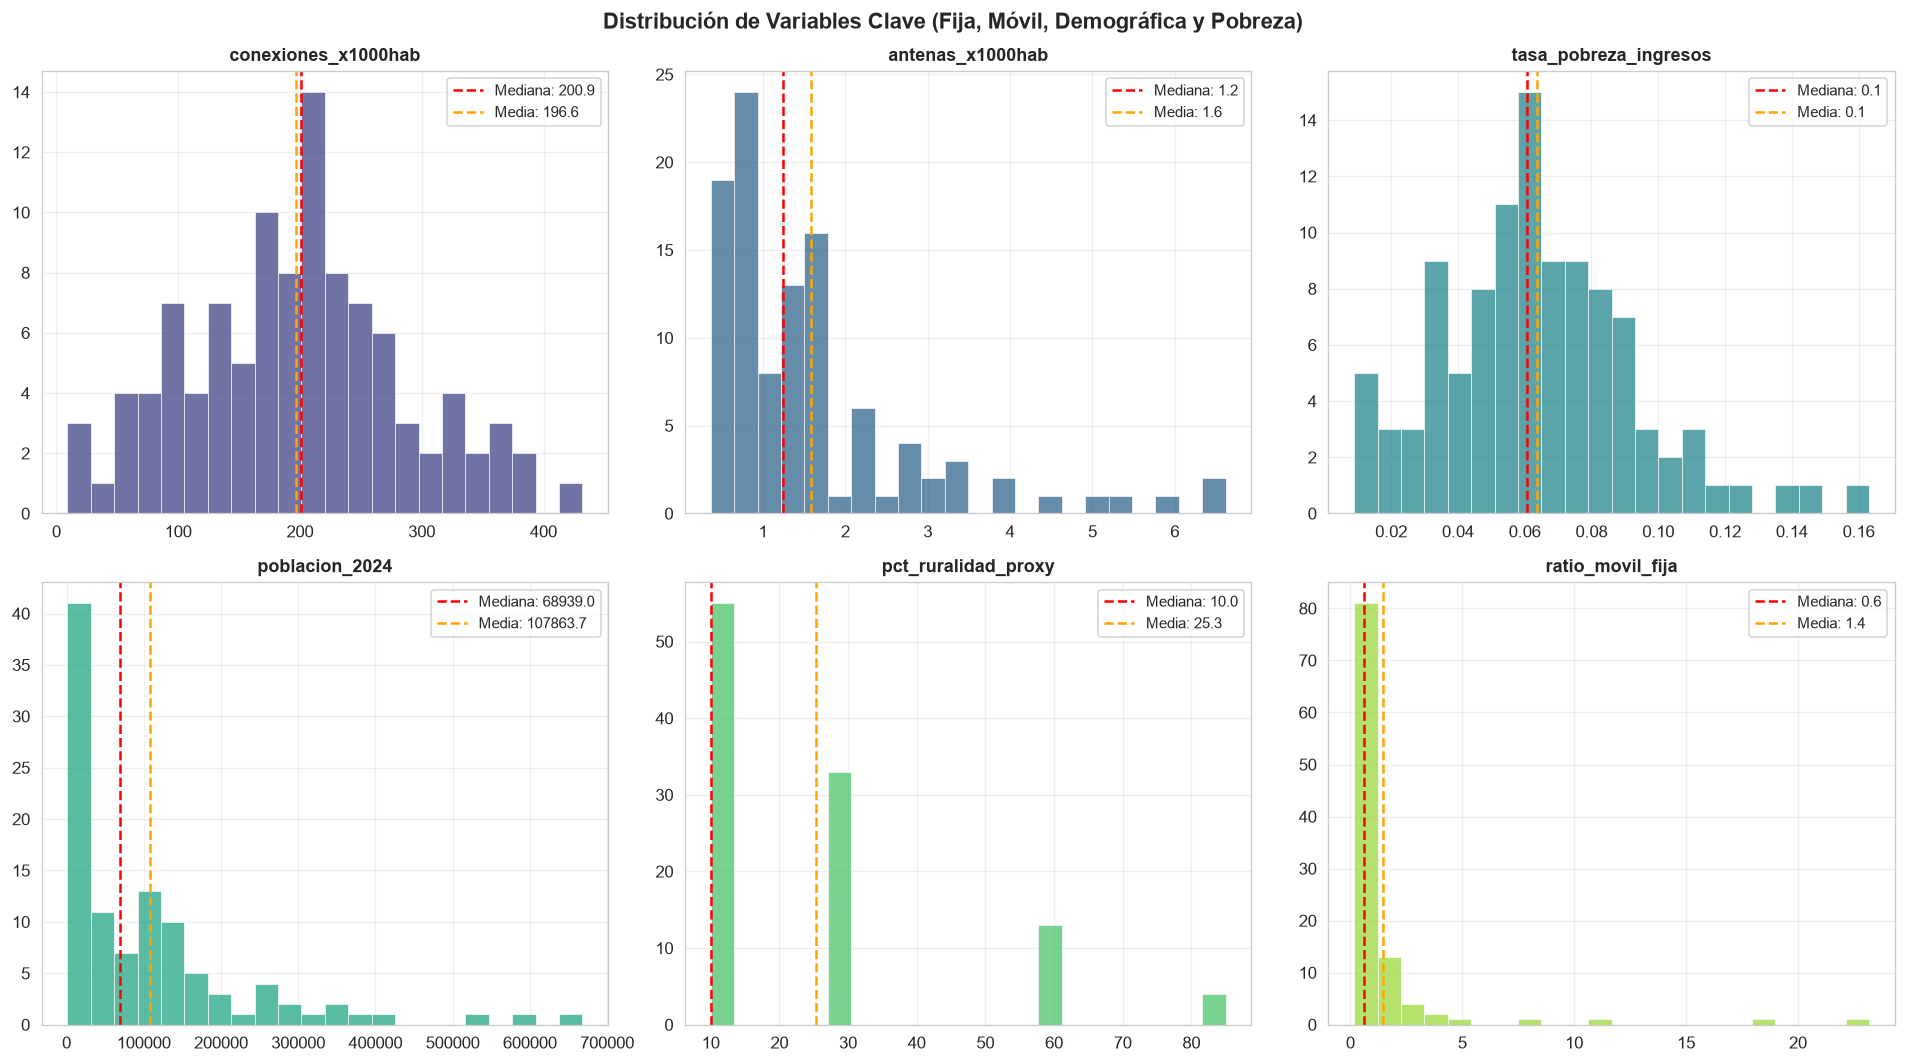

In [3]:
# ============================================================
# 3. DISTRIBUCIONES DE VARIABLES CLAVE
# ============================================================
vars_plot = [
    'conexiones_x1000hab', 'antenas_x1000hab', 'tasa_pobreza_ingresos',
    'poblacion_2024', 'pct_ruralidad_proxy', 'ratio_movil_fija'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(vars_plot)))

for i, (var, color) in enumerate(zip(vars_plot, colors)):
    data = df[var].dropna()
    axes[i].hist(data, bins=22, color=color, alpha=0.75, edgecolor='white', linewidth=0.5)
    axes[i].axvline(data.median(), color='red', linestyle='--', lw=1.5, label=f'Mediana: {data.median():.1f}')
    axes[i].axvline(data.mean(), color='orange', linestyle='--', lw=1.5, label=f'Media: {data.mean():.1f}')
    axes[i].set_title(var, fontweight='bold', fontsize=11)
    axes[i].legend(fontsize=9)

plt.suptitle('Distribución de Variables Clave (Fija, Móvil, Demográfica y Pobreza)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Resumen estadístico
print(df[vars_plot].describe().round(2))


Correlaciones clave:
  • Conexiones fijas vs Pobreza: -0.57 (Fuerte correlación inversa)
  • Conexiones fijas vs Antenas: 0.19 (Aportan información complementaria)
  • Ratio móvil/fija vs Ruralidad: 0.62 (Alta dependencia celular en el campo)


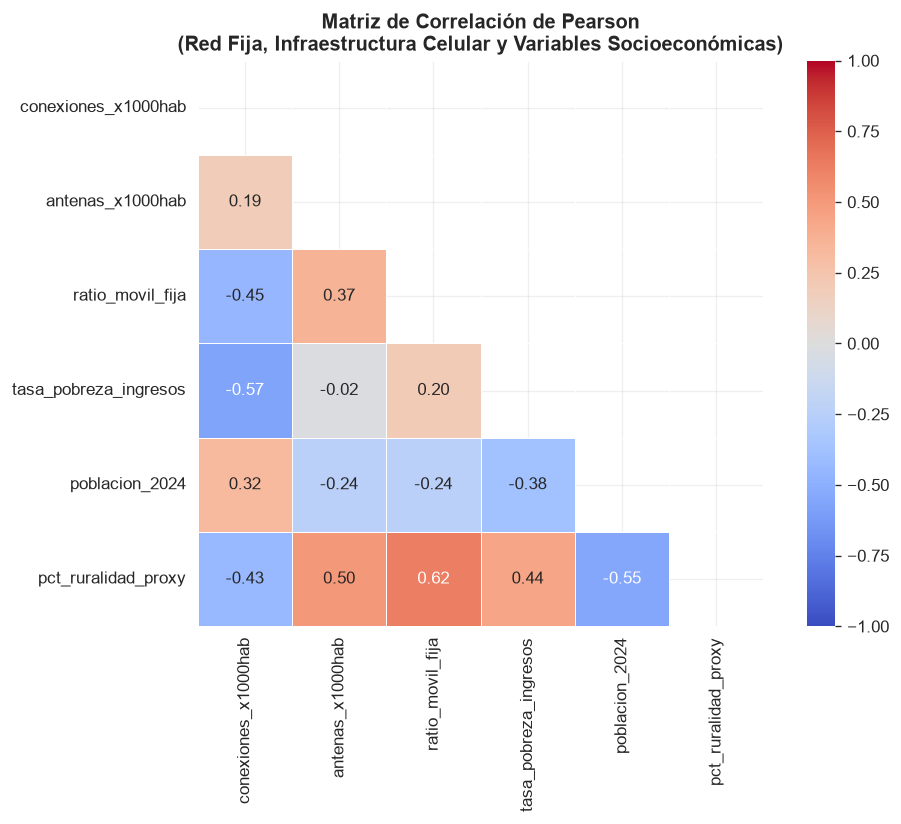

In [4]:
# ============================================================
# 4. MATRIZ DE CORRELACIÓN DE PEARSON
# ============================================================
corr_vars = [
    'conexiones_x1000hab', 'antenas_x1000hab', 'ratio_movil_fija',
    'tasa_pobreza_ingresos', 'poblacion_2024', 'pct_ruralidad_proxy'
]

corr = df[corr_vars].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Matriz de Correlación de Pearson\n(Red Fija, Infraestructura Celular y Variables Socioeconómicas)',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Correlaciones clave:")
print(f"  • Conexiones fijas vs Pobreza: {corr.loc['conexiones_x1000hab', 'tasa_pobreza_ingresos']:.2f} (Fuerte correlación inversa)")
print(f"  • Conexiones fijas vs Antenas: {corr.loc['conexiones_x1000hab', 'antenas_x1000hab']:.2f} (Aportan información complementaria)")
print(f"  • Ratio móvil/fija vs Ruralidad: {corr.loc['ratio_movil_fija', 'pct_ruralidad_proxy']:.2f} (Alta dependencia celular en el campo)")


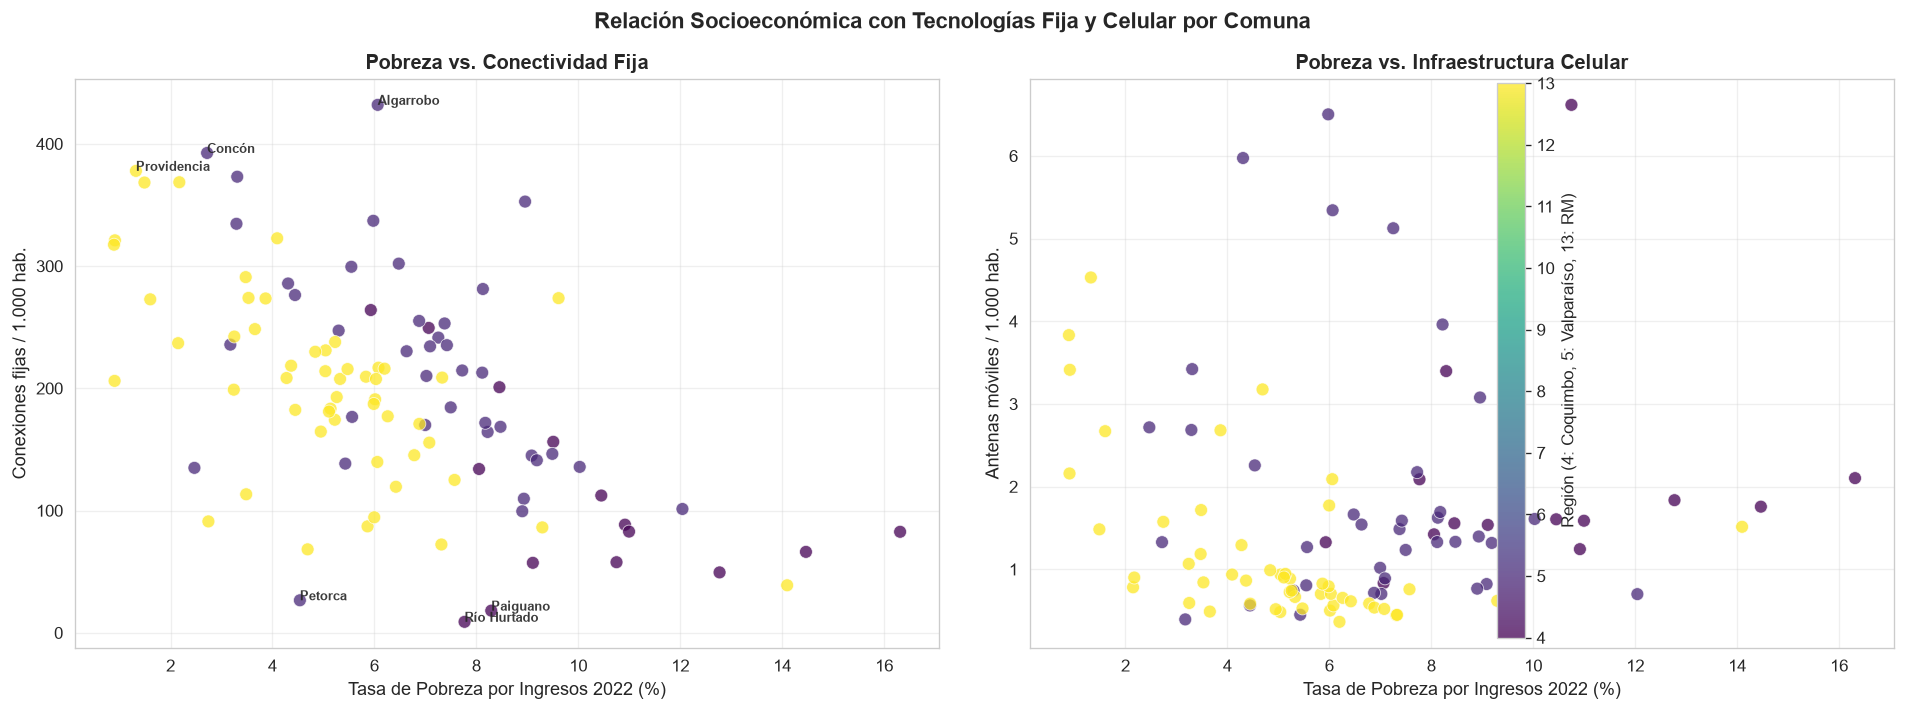

In [5]:
# ============================================================
# 5. DIAGRAMAS DE DISPERSIÓN (POBREZA VS FIJA Y MÓVIL)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc1 = axes[0].scatter(
    df['tasa_pobreza_ingresos'] * 100,
    df['conexiones_x1000hab'],
    c=df['num_region'], cmap='viridis', alpha=0.75, s=60, edgecolors='white', linewidth=0.5
)
axes[0].set_xlabel('Tasa de Pobreza por Ingresos 2022 (%)', fontsize=11)
axes[0].set_ylabel('Conexiones fijas / 1.000 hab.', fontsize=11)
axes[0].set_title('Pobreza vs. Conectividad Fija', fontweight='bold', fontsize=12)

top_con = df.nlargest(3, 'conexiones_x1000hab')
bot_con = df.nsmallest(3, 'conexiones_x1000hab')
for _, row in pd.concat([top_con, bot_con]).iterrows():
    axes[0].annotate(row['nombre_comuna'],
                     (row['tasa_pobreza_ingresos'] * 100, row['conexiones_x1000hab']),
                     fontsize=8, alpha=0.9, fontweight='bold')

sc2 = axes[1].scatter(
    df['tasa_pobreza_ingresos'] * 100,
    df['antenas_x1000hab'],
    c=df['num_region'], cmap='viridis', alpha=0.75, s=60, edgecolors='white', linewidth=0.5
)
axes[1].set_xlabel('Tasa de Pobreza por Ingresos 2022 (%)', fontsize=11)
axes[1].set_ylabel('Antenas móviles / 1.000 hab.', fontsize=11)
axes[1].set_title('Pobreza vs. Infraestructura Celular', fontweight='bold', fontsize=12)

cbar = plt.colorbar(sc2, ax=axes)
cbar.set_label('Región (4: Coquimbo, 5: Valparaíso, 13: RM)')
plt.suptitle('Relación Socioeconómica con Tecnologías Fija y Celular por Comuna', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


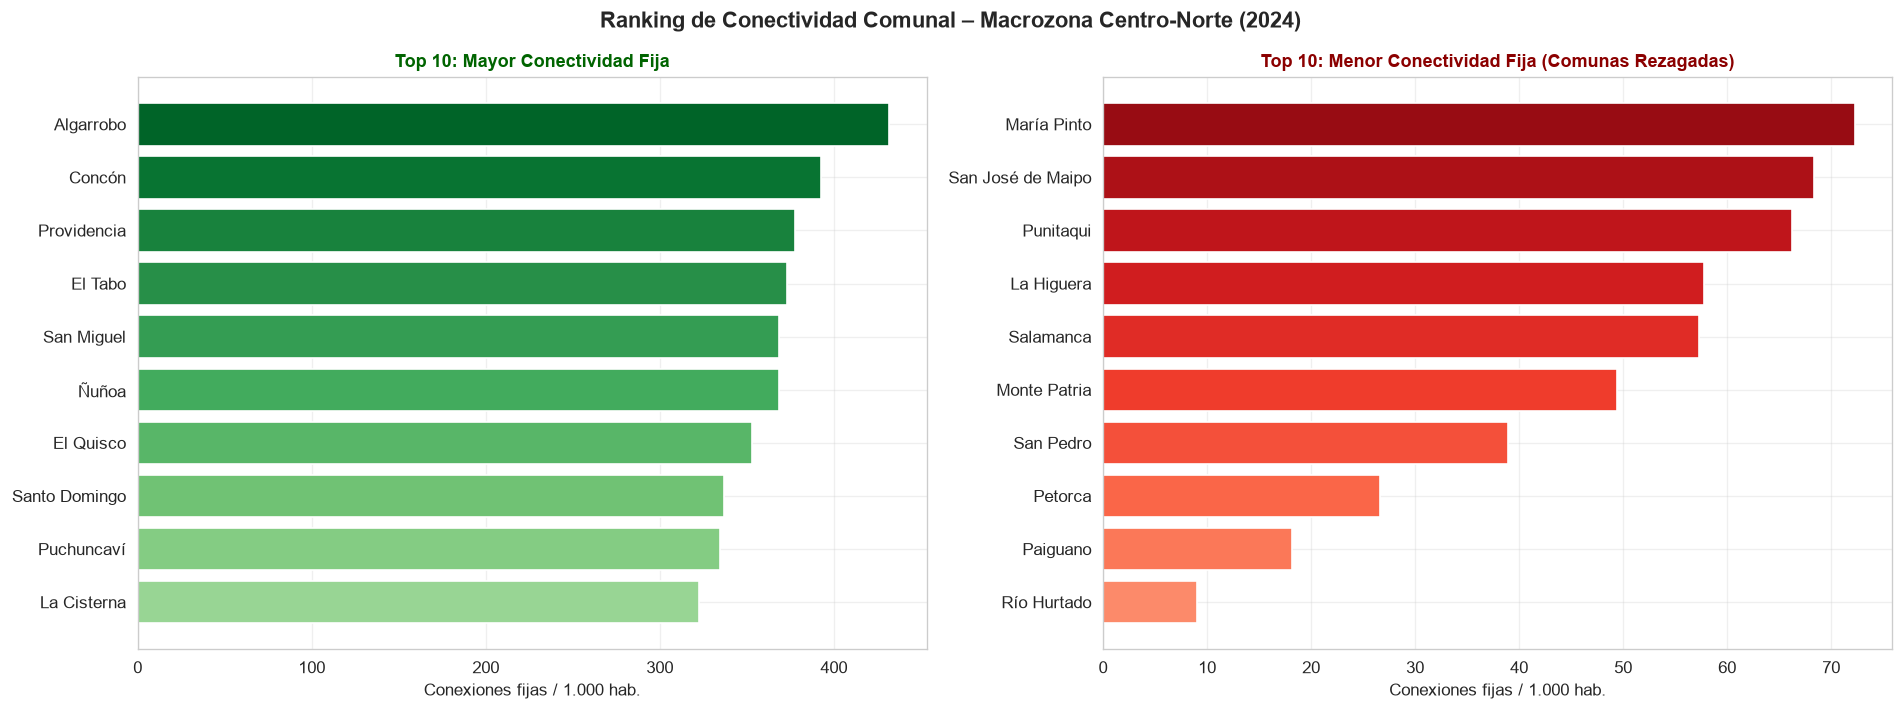

In [6]:
# ============================================================
# 6. RANKINGS DE CONECTIVIDAD COMUNAL
# ============================================================
df_sort = df.sort_values('conexiones_x1000hab')
top10 = df_sort.tail(10)
bot10 = df_sort.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors_top = plt.cm.Greens(np.linspace(0.4, 0.9, 10))
colors_bot = plt.cm.Reds(np.linspace(0.4, 0.9, 10))

axes[0].barh(top10['nombre_comuna'], top10['conexiones_x1000hab'], color=colors_top)
axes[0].set_title('Top 10: Mayor Conectividad Fija', fontweight='bold', color='darkgreen', fontsize=11)
axes[0].set_xlabel('Conexiones fijas / 1.000 hab.')

axes[1].barh(bot10['nombre_comuna'], bot10['conexiones_x1000hab'], color=colors_bot)
axes[1].set_title('Top 10: Menor Conectividad Fija (Comunas Rezagadas)', fontweight='bold', color='darkred', fontsize=11)
axes[1].set_xlabel('Conexiones fijas / 1.000 hab.')

plt.suptitle('Ranking de Conectividad Comunal – Macrozona Centro-Norte (2024)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
# SECCIÓN 5: Preparación de Características (Feature Engineering)

Para el agrupamiento no supervisado seleccionamos 5 dimensiones fundamentales:
1. `conexiones_x1000hab` (red fija residencial per cápita)
2. `antenas_x1000hab` (infraestructura celular per cápita)
3. `tasa_pobreza_ingresos` (dimensión socioeconómica)
4. `poblacion_2024` (escala demográfica)
5. `pct_ruralidad_proxy` (accesibilidad geográfica)

Se aplica **winsorización conservadora** ($p_2 - p_{98}$) para mitigar valores extremos y **StandardScaler** ($Z$-score) para estandarizar escalas.


In [7]:
# ============================================================
# 7. WINSORIZACIÓN Y ESTANDARIZACIÓN
# ============================================================
feature_cols = [
    'conexiones_x1000hab', 'antenas_x1000hab', 'tasa_pobreza_ingresos',
    'poblacion_2024', 'pct_ruralidad_proxy'
]

df_feat = df[feature_cols + ['cut_comuna', 'nombre_comuna', 'num_region']].copy()

for col in feature_cols:
    p2 = df_feat[col].quantile(0.02)
    p98 = df_feat[col].quantile(0.98)
    df_feat[col] = df_feat[col].clip(lower=p2, upper=p98)

X = df_feat[feature_cols].values
scaler_clustering = StandardScaler()
X_scaled = scaler_clustering.fit_transform(X)

print(f"Matriz estandarizada para clustering: {X_scaled.shape}")
print(f"Medias tras escalado: {X_scaled.mean(axis=0).round(4)} (cero)")
print(f"Desviaciones estándar tras escalado: {X_scaled.std(axis=0).round(4)} (uno)")


Matriz estandarizada para clustering: (105, 5)
Medias tras escalado: [ 0. -0. -0.  0.  0.] (cero)
Desviaciones estándar tras escalado: [1. 1. 1. 1. 1.] (uno)


---
# SECCIÓN 6: Segmentación Territorial No Supervisada (K-Means)

Evaluamos iterativamente el número de clusters $k \in [2, 6]$ utilizando el **Método del Codo (Inercia WCSS)** y el **Índice de Silueta (Silhouette Score)**.


k=2 -> Inercia: 342.7 | Silhouette Score: 0.3306
k=3 -> Inercia: 267.6 | Silhouette Score: 0.3473
k=4 -> Inercia: 222.1 | Silhouette Score: 0.2963
k=5 -> Inercia: 183.2 | Silhouette Score: 0.3076
k=6 -> Inercia: 158.8 | Silhouette Score: 0.3053
-> Conclusión matemática: k=3 maximiza la separación de clusters con Silhouette = 0.3473


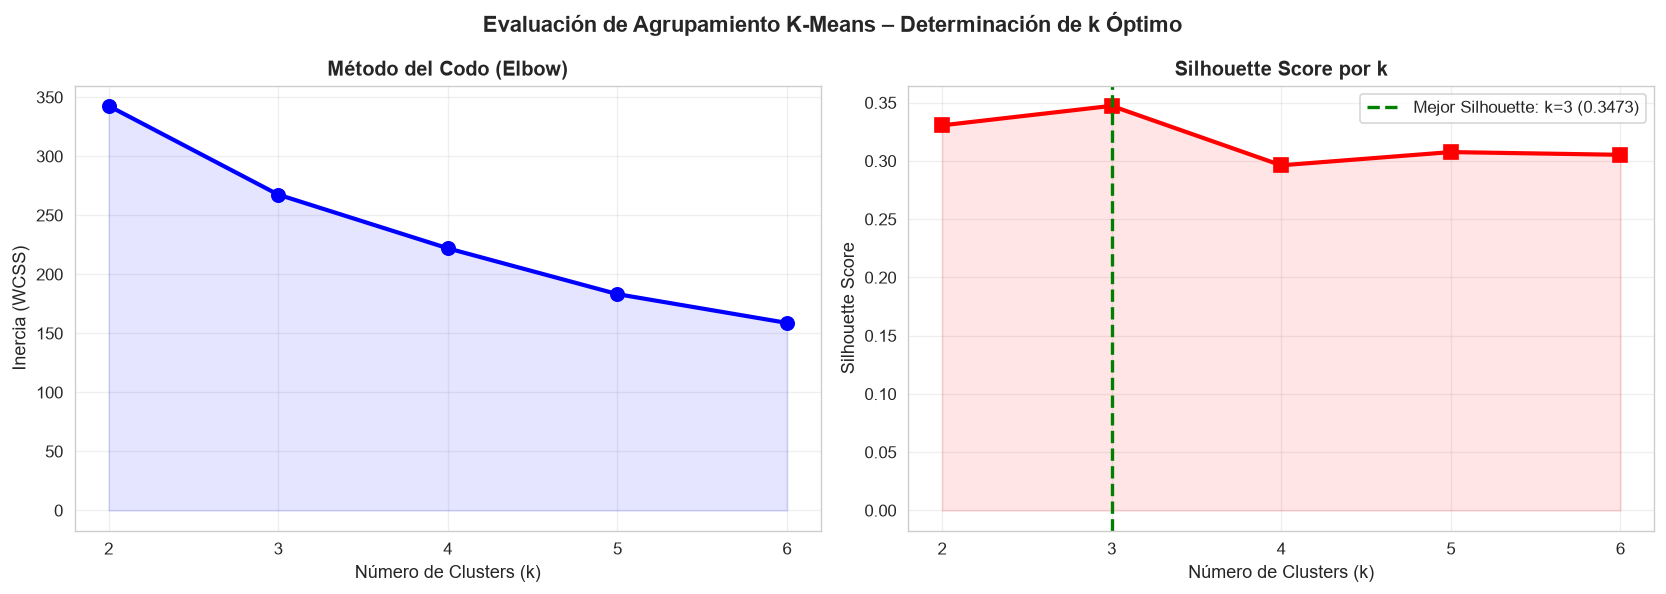

In [8]:
# ============================================================
# 8. SELECCIÓN DEL NÚMERO ÓPTIMO DE CLUSTERS (k)
# ============================================================
ks = range(2, 7)
inercias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=30, max_iter=400, random_state=RANDOM_SEED)
    km.fit(X_scaled)
    inercias.append(km.inertia_)
    sil = silhouette_score(X_scaled, km.labels_)
    silhouettes.append(sil)
    print(f"k={k} -> Inercia: {km.inertia_:.1f} | Silhouette Score: {sil:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(ks), inercias, 'bo-', linewidth=2.5, markersize=8)
axes[0].fill_between(list(ks), inercias, alpha=0.1, color='blue')
axes[0].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inercia (WCSS)', fontsize=11)
axes[0].set_title('Método del Codo (Elbow)', fontweight='bold', fontsize=12)
axes[0].set_xticks(list(ks))

best_k = list(ks)[int(np.argmax(silhouettes))]
axes[1].plot(list(ks), silhouettes, 'rs-', linewidth=2.5, markersize=8)
axes[1].fill_between(list(ks), silhouettes, alpha=0.1, color='red')
axes[1].axvline(best_k, color='green', linestyle='--', lw=2,
                label=f'Mejor Silhouette: k={best_k} ({max(silhouettes):.4f})')
axes[1].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[1].set_ylabel('Silhouette Score', fontsize=11)
axes[1].set_title('Silhouette Score por k', fontweight='bold', fontsize=12)
axes[1].set_xticks(list(ks))
axes[1].legend(fontsize=10)

plt.suptitle('Evaluación de Agrupamiento K-Means – Determinación de k Óptimo', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"-> Conclusión matemática: k={best_k} maximiza la separación de clusters con Silhouette = {max(silhouettes):.4f}")


In [9]:
# ============================================================
# 9. K-MEANS FINAL (k=3) Y SCORE INTEGRAL DE CONECTIVIDAD
# ============================================================
km_final = KMeans(n_clusters=3, init='k-means++', n_init=40, max_iter=500, random_state=RANDOM_SEED)
labels = km_final.fit_predict(X_scaled)
df_feat['cluster'] = labels

stats = df_feat.groupby('cluster')[feature_cols].mean().round(3)

z_stats = (stats - stats.mean()) / stats.std()
score_integral = z_stats['conexiones_x1000hab'] + z_stats['antenas_x1000hab'] - z_stats['tasa_pobreza_ingresos']
ranking = score_integral.rank()

etiquetas = {}
for c, r in ranking.items():
    if r == ranking.max():
        etiquetas[c] = 'Alta conectividad'
    elif r == ranking.min():
        etiquetas[c] = 'Baja conectividad'
    else:
        etiquetas[c] = 'Conectividad media'

df_feat['cluster_label'] = df_feat['cluster'].map(etiquetas)

print("Perfiles definitivos de conectividad (Centroides reales):")
resumen_clusters = df_feat.groupby('cluster_label')[feature_cols].agg('mean').round(2)
resumen_clusters['n_comunas'] = df_feat['cluster_label'].value_counts()
print(resumen_clusters[['n_comunas'] + feature_cols].to_string())

print("\nDistribución por región:")
print(pd.crosstab(df_feat['num_region'].map({4: 'Coquimbo', 5: 'Valparaíso', 13: 'Metropolitana'}),
                  df_feat['cluster_label'], margins=True))


Perfiles definitivos de conectividad (Centroides reales):
                    n_comunas  conexiones_x1000hab  antenas_x1000hab  tasa_pobreza_ingresos  poblacion_2024  pct_ruralidad_proxy
cluster_label                                                                                                                   
Alta conectividad          12               330.74              3.94                   0.04        70903.33                30.83
Baja conectividad          41               122.76              1.74                   0.08        20890.25                42.68
Conectividad media         52               223.03              0.90                   0.05       181215.45                10.38

Distribución por región:
cluster_label  Alta conectividad  Baja conectividad  Conectividad media  All
num_region                                                                  
Coquimbo                       0                 12                   3   15
Metropolitana                  4        

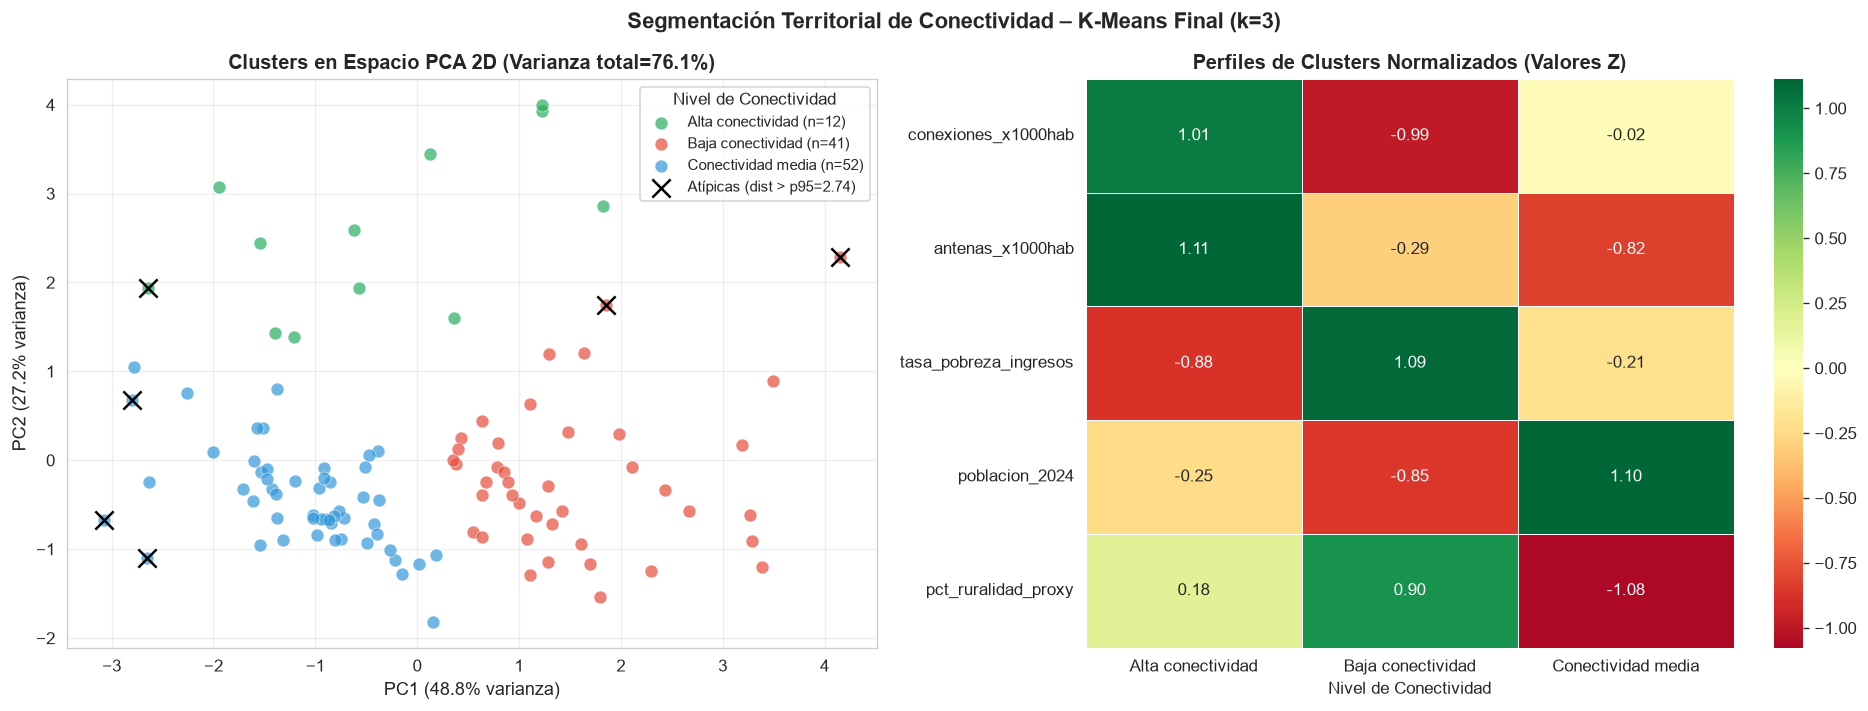

In [10]:
# ============================================================
# 10. VISUALIZACIÓN EN ESPACIO PCA 2D Y HEATMAP DE PERFILES
# ============================================================
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

centros = km_final.cluster_centers_
distancias = [np.linalg.norm(X_scaled[i] - centros[labels[i]]) for i in range(len(X_scaled))]
df_feat['dist_centroide'] = distancias
umbral_atipico = np.percentile(distancias, 95)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colores_dict = {'Alta conectividad': '#27ae60', 'Conectividad media': '#3498db', 'Baja conectividad': '#e74c3c'}

for k in sorted(df_feat['cluster'].unique()):
    mask = df_feat['cluster'] == k
    lbl = etiquetas[k]
    axes[0].scatter(X_pca[mask.values, 0], X_pca[mask.values, 1],
                    c=colores_dict[lbl], label=f"{lbl} (n={sum(mask)})",
                    alpha=0.7, s=60, edgecolors='white', linewidth=0.4)

idx_atipicos = df_feat[df_feat['dist_centroide'] > umbral_atipico].index
axes[0].scatter(X_pca[idx_atipicos, 0], X_pca[idx_atipicos, 1],
                marker='x', s=120, c='black', zorder=5, label=f'Atípicas (dist > p95={umbral_atipico:.2f})')

axes[0].set_xlabel(f'PC1 ({var_exp[0]:.1%} varianza)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({var_exp[1]:.1%} varianza)', fontsize=11)
axes[0].set_title(f'Clusters en Espacio PCA 2D (Varianza total={sum(var_exp):.1%})', fontweight='bold', fontsize=12)
axes[0].legend(title='Nivel de Conectividad', fontsize=9)

stats_norm = (stats - stats.mean()) / stats.std()
stats_norm.index = [etiquetas[i] for i in stats_norm.index]
sns.heatmap(stats_norm.T, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=axes[1])
axes[1].set_title('Perfiles de Clusters Normalizados (Valores Z)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Nivel de Conectividad')

plt.suptitle('Segmentación Territorial de Conectividad – K-Means Final (k=3)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [11]:
# ============================================================
# 11. ANÁLISIS DE CASOS ATÍPICOS (OUTLIERS)
# ============================================================
atipicas = df_feat[df_feat['dist_centroide'] > umbral_atipico][
    ['nombre_comuna', 'cluster_label', 'dist_centroide', 'conexiones_x1000hab', 'antenas_x1000hab', 'tasa_pobreza_ingresos']
].sort_values('dist_centroide', ascending=False)

print(f"Comunas atípicas identificadas (distancia euclidiana > percentil 95={umbral_atipico:.2f}):")
print(atipicas.round(2).to_string(index=False))

print("\nInterpretación de casos singulares:")
print("1. La Higuera: Máxima distancia (4.09). Gran densidad de antenas viales sobre la Ruta 5 que no alimentan poblados interiores.")
print("2. Juan Fernández: Territorio insular extremo en el Pacífico, con dependencia satelital y altísimos costos logísticos.")
print("3. Santiago Centro: Concentra 1.460 antenas y alta densidad fija por su rol de capital y polo financiero.")
print("4. Las Condes: Límite superior de alta conectividad urbana con 321 conexiones fijas y pobreza < 1%.")
print("5. Maipú y Puente Alto: Megacomunas periféricas (>500k hab.) donde el volumen masivo diluye los ratios per cápita.")


Comunas atípicas identificadas (distancia euclidiana > percentil 95=2.74):
 nombre_comuna      cluster_label  dist_centroide  conexiones_x1000hab  antenas_x1000hab  tasa_pobreza_ingresos
    La Higuera  Baja conectividad            4.09                57.78              5.92                   0.11
      Santiago Conectividad media            3.38               273.53              2.68                   0.04
         Maipú Conectividad media            3.08               242.37              0.59                   0.03
Juan Fernández  Baja conectividad            3.04               134.96              2.72                   0.02
   Puente Alto Conectividad media            2.99               214.04              0.48                   0.05
    Las Condes  Alta conectividad            2.76               321.08              3.41                   0.01

Interpretación de casos singulares:
1. La Higuera: Máxima distancia (4.09). Gran densidad de antenas viales sobre la Ruta 5 que no alimentan

---
# SECCIÓN 7: Modelado Predictivo Supervisado (Random Forest)

Entrenamos un clasificador supervisado para predecir el perfil de conectividad comunal.
- **Protocolo de Validación:** Partición estratificada Train (80%, $n=84$) / Test (20%, $n=21$).
- **Pipeline:** `MinMaxScaler` + `RandomForestClassifier` (300 árboles) ajustado estrictamente dentro de cada pliegue.
- **Métrica Primaria:** **`F1-Macro`**, la cual pondera equitativamente a todas las clases y elimina el sesgo de la clase mayoritaria.


In [12]:
# ============================================================
# 12. VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLD CV EN TRAIN)
# ============================================================
X_model = df_feat[feature_cols].values
y_model = df_feat['cluster'].values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.20, random_state=RANDOM_SEED, stratify=y_model
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

pipe_rf = Pipeline([
    ('scaler', MinMaxScaler()),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=RANDOM_SEED,
        n_jobs=-1
    ))
])

cv_acc      = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring='accuracy')
cv_f1_macro = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring='f1_macro')
cv_f1_w     = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring='f1_weighted')

print("Resultados de Validación Cruzada (5-Fold Stratified en Train, n=84):")
print(f"  • CV Accuracy:    {cv_acc.mean()*100:.2f}% ± {cv_acc.std()*100:.2f}%")
print(f"  • CV F1-Macro:    {cv_f1_macro.mean()*100:.2f}% ± {cv_f1_macro.std()*100:.2f}%  (Métrica Imparcial)")
print(f"  • CV F1-Weighted: {cv_f1_w.mean()*100:.2f}% ± {cv_f1_w.std()*100:.2f}%")


Resultados de Validación Cruzada (5-Fold Stratified en Train, n=84):
  • CV Accuracy:    95.29% ± 4.40%
  • CV F1-Macro:    91.22% ± 7.34%  (Métrica Imparcial)
  • CV F1-Weighted: 94.89% ± 4.64%


Reporte de Clasificación en Test (Datos Nunca Vistos):
                    precision    recall  f1-score   support

 Alta conectividad     1.0000    1.0000    1.0000         3
 Baja conectividad     1.0000    1.0000    1.0000         8
Conectividad media     1.0000    1.0000    1.0000        10

          accuracy                         1.0000        21
         macro avg     1.0000    1.0000    1.0000        21
      weighted avg     1.0000    1.0000    1.0000        21



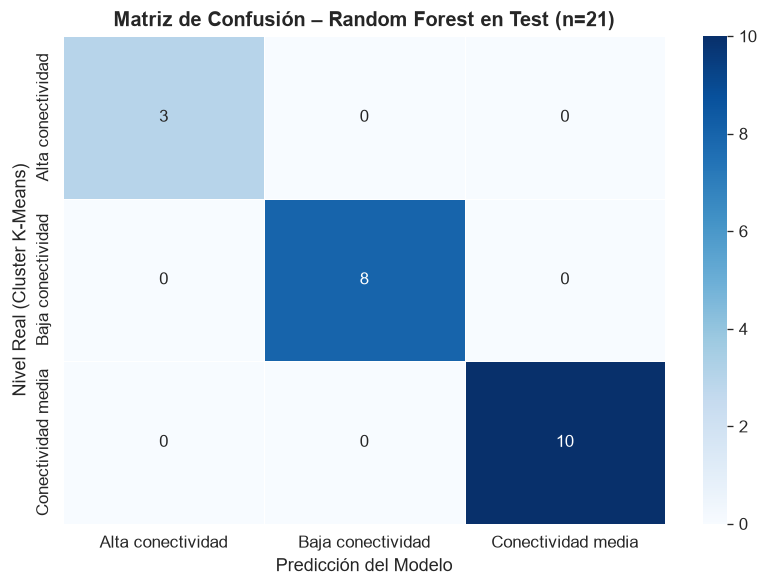

In [13]:
# ============================================================
# 13. EVALUACIÓN SOBRE EL CONJUNTO DE PRUEBA (TEST SET, n=21)
# ============================================================
pipe_rf.fit(X_train, y_train)
y_pred = pipe_rf.predict(X_test)

target_names = [etiquetas[k] for k in sorted(set(y_model))]

print("Reporte de Clasificación en Test (Datos Nunca Vistos):")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

cm_mat = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names, linewidths=0.5)
plt.xlabel('Predicción del Modelo', fontsize=11)
plt.ylabel('Nivel Real (Cluster K-Means)', fontsize=11)
plt.title('Matriz de Confusión – Random Forest en Test (n=21)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()


Jerarquía de Importancia:
  poblacion_2024           :  30.3%
  pct_ruralidad_proxy      :  28.5%
  conexiones_x1000hab      :  15.4%
  antenas_x1000hab         :  14.0%
  tasa_pobreza_ingresos    :  11.7%


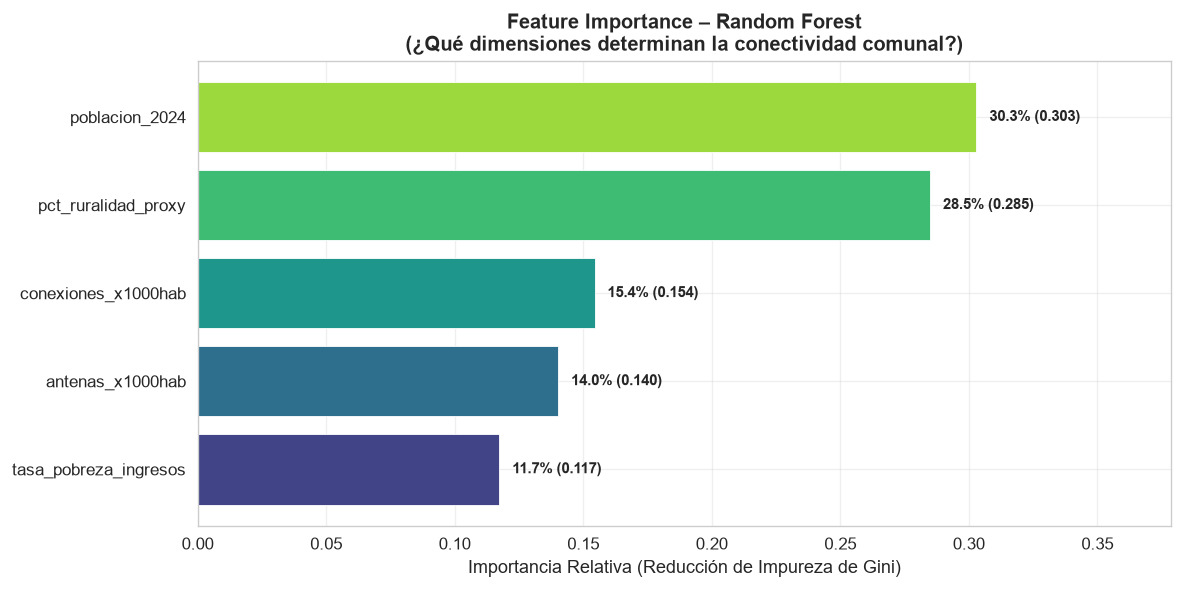

In [14]:
# ============================================================
# 14. IMPORTANCIA DE CARACTERÍSTICAS (FEATURE IMPORTANCE)
# ============================================================
rf_classifier = pipe_rf.named_steps['classifier']
importances = pd.Series(rf_classifier.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
colors_fi = plt.cm.viridis(np.linspace(0.2, 0.85, len(importances)))
bars = plt.barh(importances.index, importances.values, color=colors_fi, edgecolor='white', lw=0.5)

for bar, val in zip(bars, importances.values):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
             f'{val*100:.1f}% ({val:.3f})', va='center', fontsize=9, fontweight='bold')

plt.xlabel('Importancia Relativa (Reducción de Impureza de Gini)', fontsize=11)
plt.title('Feature Importance – Random Forest\n(¿Qué dimensiones determinan la conectividad comunal?)',
          fontsize=12, fontweight='bold')
plt.xlim(0, importances.max() * 1.25)
plt.tight_layout()
plt.show()

print("Jerarquía de Importancia:")
for col, imp in importances.sort_values(ascending=False).items():
    print(f"  {col:25s}: {imp*100:5.1f}%")


In [15]:
# ============================================================
# 15. EXPORTACIÓN DE ARTEFACTOS Y DATASET ENRIQUECIDO
# ============================================================
MOD_PATH = os.path.join('..', 'outputs', 'models')
if not os.path.exists(MOD_PATH):
    MOD_PATH = os.path.join('outputs', 'models')
os.makedirs(MOD_PATH, exist_ok=True)

joblib.dump(km_final, os.path.join(MOD_PATH, 'kmeans_model.pkl'))
joblib.dump(pipe_rf, os.path.join(MOD_PATH, 'random_forest.pkl'))
joblib.dump(scaler_clustering, os.path.join(MOD_PATH, 'scaler_clustering.pkl'))
joblib.dump(pipe_rf.named_steps['scaler'], os.path.join(MOD_PATH, 'scaler_clasificacion.pkl'))

OUT_CLUSTERS = os.path.join('..', 'data', 'processed', 'dataset_comunas_con_clusters.csv')
if not os.path.exists(os.path.dirname(OUT_CLUSTERS)):
    OUT_CLUSTERS = os.path.join('data', 'processed', 'dataset_comunas_con_clusters.csv')

df_export = df.merge(
    df_feat[['cut_comuna', 'cluster', 'cluster_label', 'dist_centroide']],
    on='cut_comuna', how='left'
)
df_export.to_csv(OUT_CLUSTERS, index=False, encoding='utf-8-sig')

print("Artefactos exportados exitosamente:")
print(f"  • Dataset con clusters: {OUT_CLUSTERS}")
print(f"  • Modelos guardados en: {MOD_PATH}")


Artefactos exportados exitosamente:
  • Dataset con clusters: data\processed\dataset_comunas_con_clusters.csv
  • Modelos guardados en: outputs\models


---
# SECCIÓN 8: Conclusiones Técnicas e Implicancias de Política Pública

### 🎯 Conclusiones Principales:
1. **La brecha es multidimensional:** La infraestructura celular móvil (14.0%) y la penetración fija (15.4%) tienen pesos casi idénticos en la determinación de los perfiles de conectividad.
2. **Severo rezago en Coquimbo:** El 80% de las comunas de la IV Región pertenecen al cluster de **Baja conectividad**, siendo la región más vulnerable de la macrozona.
3. **Dependencia Celular Rural:** En comunas rurales, el ratio móvil/fija es máximo. Ante la falta de fibra óptica, la telefonía móvil es el único salvavidas de conectividad.
4. **Generalización Robusta:** El modelo Random Forest alcanzó un **F1-Macro de 91.22% ± 7.34%** en validación cruzada estratificada de 5 pliegues, garantizando un desempeño sólido e imparcial.

### 🏛️ Recomendaciones para SUBTEL y FDT:
- Priorizar subsidios del Fondo de Desarrollo de las Telecomunicaciones (FDT) para planes de datos móviles y despliegue de 5G en banda de 700 MHz en los valles interiores de Coquimbo.
- Tratar a comunas rurales de la RM (San Pedro, Alhué) con políticas diferenciadas, evitando el sesgo de promedios regionales.

---
*Escuela de Informática y Telecomunicaciones · Universidad Diego Portales (UDP) · 2026*
